## imports:

In [1]:
import json
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt



## audit:


In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW, PROC, REP = ROOT/"data/raw", ROOT/"data/processed", ROOT/"reports"
for d in (RAW, PROC, REP):
    d.mkdir(parents=True, exist_ok=True)

SPLIT_SEED = 2026
MASK_SEED  = "digikala-semi-supervised-v1"
MASK_RATE  = 0.20

CSV = RAW / "digikala-comments.csv"
print(CSV, "exists:", CSV.exists(), "| size GB:", round(CSV.stat().st_size/1e9, 2))

e:\maktab seesion\home work\code\project-3\data\raw\digikala-comments.csv exists: True | size GB: 1.28


## Quality gate:

In [3]:
con = duckdb.connect()
con.execute("SET memory_limit='6GB';")            
con.execute(f"SET threads={os.cpu_count()};")
con.execute(f"SET temp_directory='{(PROC/'duck_tmp').as_posix()}';")

PQ = PROC / "comments.parquet"
con.execute(f"""
COPY (
  SELECT * FROM read_csv('{CSV.as_posix()}', header=true, all_varchar=true,quote='"', escape='"')) TO '{PQ.as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 200000)""")
P = f"read_parquet('{PQ.as_posix()}')"

print(con.execute(f"DESCRIBE SELECT * FROM {P}").df()[["column_name","column_type"]])
print(con.execute(f"SELECT count() AS n_rows FROM {P}").df())
print(con.execute(f"SELECT * FROM {P} LIMIT 3").df().T)

              column_name column_type
0                      id     VARCHAR
1                   title     VARCHAR
2                    body     VARCHAR
3              created_at     VARCHAR
4                    rate     VARCHAR
5   recommendation_status     VARCHAR
6                is_buyer     VARCHAR
7              product_id     VARCHAR
8              advantages     VARCHAR
9           disadvantages     VARCHAR
10                  likes     VARCHAR
11               dislikes     VARCHAR
12           seller_title     VARCHAR
13            seller_code     VARCHAR
14      true_to_size_rate     VARCHAR
    n_rows
0  6156289
                                     0  \
id                            53672599   
title                   پیشنهاد نمیشود   
body                   به درد نمیخوره    
created_at              23 شهریور 1402   
rate                               1.0   
recommendation_status  not_recommended   
is_buyer                          True   
product_id                      25

In [4]:
# con = duckdb.connect()
# p = f"read_paraquet('{(PROC/'comments.paraquet').as_posix()}')"

In [5]:
expected = ["id","title","body","created_at","rate","recommendation_status",
            "is_buyer","product_id","advantages","disadvantages","likes",
            "dislikes","seller_title","seller_code","true_to_size_rate"]
actual = con.execute(f"DESCRIBE SELECT * FROM {P}").df()["column_name"].tolist()
print("missing columns:", [c for c in expected if c not in actual])
print("extra columns  :", [c for c in actual if c not in expected])

gate = con.execute(f"""
SELECT
  count(*)                                                       AS n_rows,
  count(*) - count(DISTINCT id)                                  AS dup_ids,
  count(*) FILTER (WHERE body IS NULL OR trim(body) = '')        AS empty_body,
  count(*) FILTER (WHERE rate IS NULL OR trim(rate) = '')        AS rate_missing,
  count(*) FILTER (WHERE trim(rate) <> '' AND TRY_CAST(rate AS DOUBLE) IS NULL) AS rate_non_numeric,
  count(*) FILTER (WHERE TRY_CAST(rate AS DOUBLE) NOT BETWEEN 0 AND 5)          AS rate_out_of_range,
  min(TRY_CAST(rate AS DOUBLE))                                  AS rate_min,
  max(TRY_CAST(rate AS DOUBLE))                                  AS rate_max,
  count(DISTINCT rate)                                           AS rate_n_unique,
  count(DISTINCT product_id)                                     AS n_products,
  count(DISTINCT seller_code)                                    AS n_sellers
FROM {P}
""").df().T
print(gate)

labels = con.execute(f"""
SELECT recommendation_status, count(*) AS n FROM {P}
GROUP BY 1 ORDER BY n DESC""").df()
print(labels)

rates = con.execute(f"""
SELECT 
    rate,
    count(*) AS n,
    round(count(*) * 100.0 / sum(count(*)) OVER (), 2) AS pct,
    round(sum(count(*)) OVER (ORDER BY count(*) DESC) * 100.0 / sum(count(*)) OVER (), 2) AS cumulative_pct
FROM {P}
GROUP BY rate
ORDER BY n DESC
LIMIT 20
""").df()
print(rates)

gate.to_csv(REP/"quality_gate.csv")
labels.to_csv(REP/"label_vocab.csv", index=False)
rates.to_csv(REP/"rate_distribution.csv", index=False)

missing columns: []
extra columns  : []
                           0
n_rows             6156289.0
dup_ids               3229.0
empty_body               0.0
rate_missing             0.0
rate_non_numeric         0.0
rate_out_of_range        1.0
rate_min                 0.0
rate_max              2500.0
rate_n_unique          178.0
n_products          331599.0
n_sellers            29214.0
  recommendation_status        n
0           recommended  4162839
1                   nan   894426
2               no_idea   594121
3       not_recommended   504903
    rate        n    pct  cumulative_pct
0    5.0  2398801  38.97           38.97
1    4.0  1515723  24.62           63.59
2    3.0   958799  15.57           79.16
3    0.0   529098   8.59           87.75
4    1.0   327662   5.32           93.08
5    2.0   198077   3.22           96.29
6    4.5    13479   0.22           96.51
7    3.5    12207   0.20           96.71
8   4.25    11653   0.19           96.90
9   3.75    10045   0.16           97

## A1

count    331599.000000
mean         18.565463
std          40.934097
min           1.000000
50%           4.000000
90%          46.000000
99%         200.000000
max         400.000000
Name: n, dtype: float64
Share of top 10 products in total reviews: 0.05 %
Products with more than 1000 reviews: 0


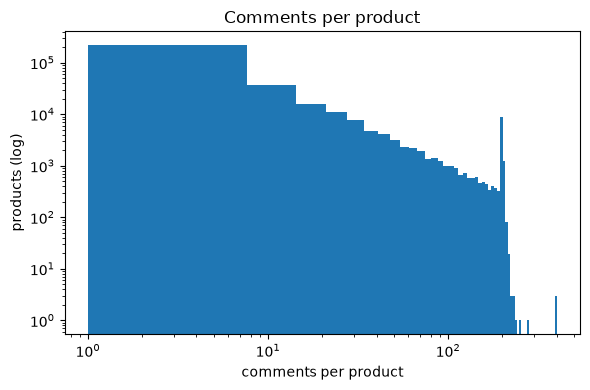

In [6]:
n_rows = con.execute(f"SELECT count() FROM {P}").fetchone()[0]
per_product = con.execute(f"""SELECT product_id, count(*) AS n FROM {P} GROUP BY 1""").df()

print(per_product["n"].describe(percentiles=[.5, .9, .99]))
top10_share = per_product.nlargest(10, "n")["n"].sum() / n_rows
print("Share of top 10 products in total reviews:", round(100*top10_share, 2), "%")
print("Products with more than 1000 reviews:", (per_product["n"] > 1000).sum())

plt.figure(figsize=(6,4))
plt.hist(per_product["n"], bins=60, log=True)
plt.xscale("log"); plt.xlabel("comments per product"); 
plt.ylabel("products (log)")
plt.title("Comments per product"); plt.tight_layout()
plt.savefig(REP/"fig1_comments_per_product.png", dpi=150); plt.show()

## A2

In [7]:
cols = con.execute(f"DESCRIBE SELECT * FROM {P}").df()["column_name"].tolist()
sel = ", ".join(
    f"count(*) FILTER (WHERE \"{c}\" IS NULL OR trim(lower(\"{c}\")) IN ('', 'nan', 'null', 'none')) AS \"{c}\""
    for c in cols)
miss = con.execute(f"SELECT {sel} FROM {P}").df().T.rename(columns={0: "missing"})
miss["pct"] = (100 * miss["missing"] / n_rows).round(2)
print(miss.sort_values("pct", ascending=False))
miss.to_csv(REP/"missing_by_column.csv")

lab_missing = "(recommendation_status IS NULL OR trim(lower(recommendation_status)) IN ('', 'nan', 'null', 'none'))"
print(con.execute(f"""
SELECT {lab_missing} AS label_missing, is_buyer, count(*) AS n
FROM {P} GROUP BY 1,2 ORDER BY 1,2""").df())

print(con.execute(f"""
SELECT {lab_missing} AS label_missing,
       count(*) AS n,
       avg(TRY_CAST(rate AS DOUBLE)) AS mean_rate,
       quantile_cont(TRY_CAST(rate AS DOUBLE), 0.5) AS median_rate
FROM {P} GROUP BY 1""").df())

                       missing    pct
true_to_size_rate      6065516  98.53
disadvantages          5744017  93.30
advantages             5448084  88.50
title                  2866415  46.56
recommendation_status   894426  14.53
seller_title            302181   4.91
seller_code             302181   4.91
body                       637   0.01
rate                         0   0.00
created_at                   0   0.00
id                           0   0.00
is_buyer                     0   0.00
product_id                   0   0.00
likes                        0   0.00
dislikes                     0   0.00
   label_missing is_buyer        n
0          False     True  5261863
1           True    False   302181
2           True     True   592245
   label_missing        n  mean_rate  median_rate
0           True   894426   4.040810          4.0
1          False  5261863   3.581564          4.0


## A3

             label        n
0      recommended  4162839
1        <MISSING>   894426
2          no_idea   594121
3  not_recommended   504903
label  <MISSING>  no_idea  not_recommended  recommended
rate                                                   
0.00         4.8      3.9             10.9         80.5
0.05         3.1     10.3             83.5          3.1
0.10         6.1     25.8             60.6          7.6
0.15         4.4     42.0             15.5         38.1
0.20        13.8      5.0             37.1         44.2
...          ...      ...              ...          ...
4.80        13.9      1.5              0.3         84.3
4.85        12.3      1.2              0.3         86.1
4.88         0.0      0.0              0.0        100.0
4.90        12.4      1.2              0.2         86.2
5.00        18.1      0.6              0.3         81.0

[177 rows x 4 columns]


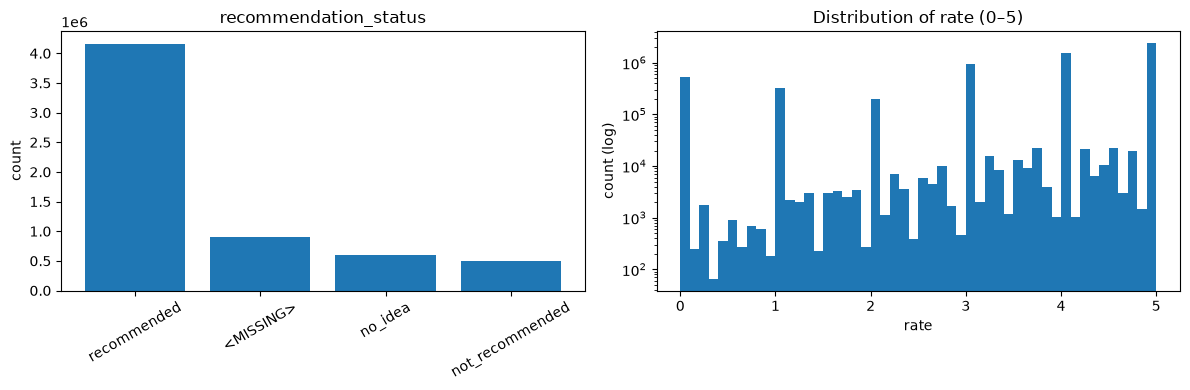

In [9]:
lab = con.execute(f"""
SELECT coalesce(nullif(trim(lower(recommendation_status)),''), '<MISSING>') AS label,
       count(*) AS n
FROM {P}
WHERE lower(recommendation_status) NOT IN ('nan','null','none')
   OR recommendation_status IS NULL
GROUP BY 1 ORDER BY n DESC""").df()

lab = con.execute(f"""
SELECT 
  CASE 
    WHEN recommendation_status IS NULL 
      OR trim(lower(recommendation_status)) IN ('', 'nan', 'null', 'none') THEN '<MISSING>'
    ELSE recommendation_status
  END AS label,
  count(*) AS n
FROM {P}
GROUP BY 1 ORDER BY n DESC""").df()
print(lab)

rt = con.execute(f"""
SELECT TRY_CAST(rate AS DOUBLE) AS rate, count(*) AS n
FROM {P}
WHERE TRY_CAST(rate AS DOUBLE) BETWEEN 0 AND 5
GROUP BY 1 ORDER BY 1""").df()

ct = con.execute(f"""
SELECT 
  CASE 
    WHEN recommendation_status IS NULL 
      OR trim(lower(recommendation_status)) IN ('', 'nan', 'null', 'none') THEN '<MISSING>'
    ELSE recommendation_status
  END AS label,
  TRY_CAST(rate AS DOUBLE) AS rate,
  count(*) AS n
FROM {P}
WHERE TRY_CAST(rate AS DOUBLE) BETWEEN 0 AND 5
GROUP BY 1,2""").df()
pivot = ct.pivot(index="rate", columns="label", values="n").fillna(0)
print((pivot.div(pivot.sum(axis=1), axis=0) * 100).round(1))


fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# label distribution
ax[0].bar(lab["label"], lab["n"])
ax[0].set_title("recommendation_status")
ax[0].tick_params(axis="x", rotation=30)
ax[0].set_ylabel("count")

# rate histogram 
ax[1].hist(rt["rate"], bins=50, weights=rt["n"], log=True)
ax[1].set_xlabel("rate")
ax[1].set_ylabel("count (log)")
ax[1].set_title("Distribution of rate (0–5)")

plt.tight_layout()
plt.savefig(REP/"fig2_labels_and_rate.png", dpi=150)
plt.show()

## A4

                                  0
char_q  [29.0, 106.0, 152.0, 297.0]
word_q      [6.0, 22.0, 32.0, 61.0]
                       0
pct_lt_20_chars    34.06
pct_lt_50_chars    70.37
pct_gt_500_chars    0.23
pct_gt_1000_chars   0.03
pct_lt_5_words     35.69
             label        n  median_char  p90_char  median_word
0      recommended  4162839         27.0      95.0          6.0
1        <MISSING>   894426         25.0     105.0          5.0
2          no_idea   594121         38.0     129.0          8.0
3  not_recommended   504903         48.0     159.0         10.0


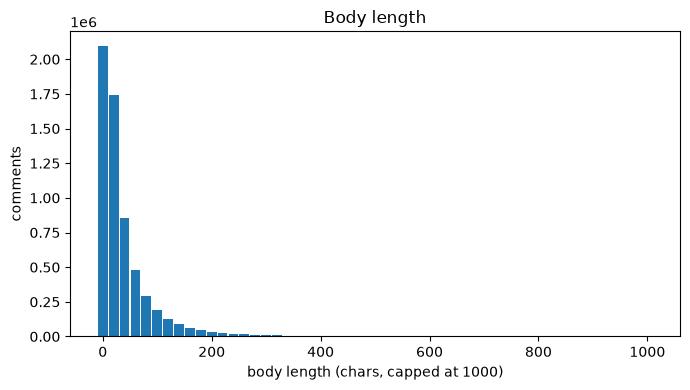

In [11]:
q = con.execute(f"""
SELECT quantile_cont(length(body), [0.5,0.9,0.95,0.99]) AS char_q,
       quantile_cont(length(body) - length(replace(body,' ','')) + 1, [0.5,0.9,0.95,0.99]) AS word_q
FROM {P} WHERE body IS NOT NULL AND trim(body) <> ''""").df()
print(q.T)

short_long = con.execute(f"""
SELECT
    round(100.0 * count(*) FILTER (WHERE length(body) < 20)   / count(*), 2) AS pct_lt_20_chars,
    round(100.0 * count(*) FILTER (WHERE length(body) < 50)   / count(*), 2) AS pct_lt_50_chars,
    round(100.0 * count(*) FILTER (WHERE length(body) > 500)  / count(*), 2) AS pct_gt_500_chars,
    round(100.0 * count(*) FILTER (WHERE length(body) > 1000) / count(*), 2) AS pct_gt_1000_chars,
    round(100.0 * count(*) FILTER (
        WHERE (length(body) - length(replace(body,' ','')) + 1) < 5
    ) / count(*), 2) AS pct_lt_5_words
FROM {P} WHERE body IS NOT NULL AND trim(body) <> ''""").df()
print(short_long.T)

len_by_label = con.execute(f"""
SELECT
    CASE
        WHEN recommendation_status IS NULL
          OR trim(lower(recommendation_status)) IN ('', 'nan', 'null', 'none') THEN '<MISSING>'
        ELSE recommendation_status
    END AS label,
    count(*) AS n,
    round(median(length(body)), 0) AS median_char,
    round(quantile_cont(length(body), 0.90), 0) AS p90_char,
    round(median(length(body) - length(replace(body,' ','')) + 1), 0) AS median_word
FROM {P}
WHERE body IS NOT NULL AND trim(body) <> ''
GROUP BY 1 ORDER BY n DESC""").df()
print(len_by_label)

hist = con.execute(f"""
SELECT (least(length(body), 1000) // 20) * 20 AS bin, count(*) AS n
FROM {P} WHERE body IS NOT NULL AND trim(body) <> ''
GROUP BY 1 ORDER BY 1""").df()

plt.figure(figsize=(7,4))
plt.bar(hist["bin"], hist["n"], width=18)
plt.xlabel("body length (chars, capped at 1000)")
plt.ylabel("comments")
plt.title("Body length")
plt.tight_layout()
plt.savefig(REP/"fig3_body_length.png", dpi=150)
plt.show()

q.to_csv(REP/"A4_quantiles.csv", index=False)
short_long.to_csv(REP/"A4_short_long.csv", index=False)
len_by_label.to_csv(REP/"A4_length_by_label.csv", index=False)

## A5

In [12]:
q1 = con.execute(f"""
SELECT any_value(body) AS body, count(*) AS n 
FROM {P}
WHERE body IS NOT NULL AND trim(body) <> ''
GROUP BY hash(body) HAVING count(*) > 1 
ORDER BY n DESC LIMIT 15""").df()
print("Q1: Top 15 repeated bodies\n", q1)

q2 = con.execute(f"""
SELECT count(*) AS n_repeated_bodies, sum(c) AS rows_in_them 
FROM (
    SELECT count(*) AS c 
    FROM {P} 
    WHERE body IS NOT NULL AND trim(body) <> ''
    GROUP BY hash(body) HAVING count(*) > 1
)""").df()
print("\nQ2: Total repeated bodies & their rows\n", q2)


q3 = con.execute(f"""
SELECT count(*) AS conflicting_labels 
FROM (
    SELECT hash(body) AS h 
    FROM {P}
    WHERE body IS NOT NULL AND trim(body) <> ''
      AND recommendation_status IS NOT NULL 
      AND trim(recommendation_status) <> ''
    GROUP BY h HAVING count(DISTINCT recommendation_status) > 1
)""").df()
print("\nQ3: Conflicting labels\n", q3)


q4 = con.execute(f"""
SELECT count(*) AS conflicting_rates
FROM (
    SELECT hash(body) AS h
    FROM {P}
    WHERE body IS NOT NULL AND trim(body) <> ''
      AND TRY_CAST(rate AS DOUBLE) BETWEEN 0 AND 5
    GROUP BY h HAVING count(DISTINCT TRY_CAST(rate AS DOUBLE)) > 1
)""").df()
print("\nQ4: Conflicting rates\n", q4)

Q1: Top 15 repeated bodies
                   body       n
0                 عالی  121349
1              خوب بود   73854
2                 خوبه   72210
3                  خوب   64297
4             عالی بود   23598
5                عالیه   19719
6               معمولی   13185
7         خیلی خوب بود   13130
8             خوب بود    12014
9        پیشنهاد میکنم   11165
10           خیلی خوبه    9738
11               عالی     9681
12  نسبت به قیمتش خوبه    8016
13             بد نیست    7960
14               خوبه     7734

Q2: Total repeated bodies & their rows
    n_repeated_bodies  rows_in_them
0             197746     2217778.0

Q3: Conflicting labels
    conflicting_labels
0               75365

Q4: Conflicting rates
    conflicting_rates
0             119538
